# Mô hình dự báo nguy cơ trễ SLA (v4): chạy lại và đánh giá trên Colab / Kaggle

Notebook này **tái lập** pipeline của dự án SME Loan: kiểm tra dữ liệu, huấn luyện lại hai mô hình, đối chiếu với kết quả trong kho mã, rồi chạy thực nghiệm bổ sung (so sánh thuật toán, nhiều hạt giống, khoảng tin cậy, bóc tách, SLA nhận biết vs cố định, độ trễ). Dữ liệu là **mô phỏng** (20.000 hồ sơ), không phải dữ liệu ngân hàng thật.

Chạy từng ô theo thứ tự. Không cần GPU.

In [2]:
from google.colab import drive
drive.mount('/content/drive')

ValueError: mount failed

## 1. Môi trường (ghi lại làm bằng chứng)

In [3]:
import sys, platform
print("Python:", sys.version)
print("Hệ điều hành:", platform.platform())
# Mô hình trong dự án được huấn luyện với đúng các phiên bản này:
!pip -q install scikit-learn==1.9.1 pandas==3.1.1 joblib numpy
import sklearn, pandas, numpy
print("scikit-learn:", sklearn.__version__, "| pandas:", pandas.__version__, "| numpy:", numpy.__version__)
# Nếu sklearn không phải 1.9.1: Runtime > Restart session rồi chạy lại ô này.

Python: 3.13.18 (main, Oct 26 2026, 15:28:15) [GCC 13.3.0]
Hệ điều hành: Linux-6.6.159+-x86_64-with-glibc2.39
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
google-colab 1.0.0 requires pandas==2.2.3, but you have pandas 3.1.1 which is incompatible.
scikit-learn: 1.9.1 | pandas: 3.1.1 | numpy: 2.4.6


/usr/local/lib/python3.13/dist-packages/pandas/core/arrays/masked.py:63: UserWarning: Pandas requires version '1.5.0' or newer of 'bottleneck' (version '1.4.2' currently installed).
  from pandas.core import (


## 2. Nạp mã và dữ liệu
**Colab:** chọn tệp `ml-experiments-v4.zip` khi hộp thoại hiện ra.
**Kaggle:** thêm tệp zip làm Dataset (Add Data > Upload), rồi bỏ comment đoạn Kaggle bên dưới và comment đoạn Colab.

In [4]:
# --- Colab ---
from google.colab import files
up = files.upload()
!unzip -q -o ml-experiments-v4.zip -d /content
%cd /content/v3

# --- Kaggle (bỏ comment, và comment đoạn Colab ở trên) ---
# !mkdir -p /kaggle/working/v3 && cd /kaggle/working && unzip -q -o /kaggle/input/<tên-dataset>/ml-experiments-v4.zip -d /kaggle/working
# %cd /kaggle/working/v3

!ls -la . data

Saving ml-experiments-v4.zip to ml-experiments-v4 (1).zip
/content/v3
.:
total 92
drwxr-xr-x 5 root root  4096 Nov 13 14:39 .
drwxr-xr-x 1 root root  4096 Nov 13 14:39 ..
-rwxrwxrwx 1 root root  7017 Nov  9 10:14 check_quality_v4.py
drwxr-xr-x 2 root root  4096 Nov 13 14:39 data
-rwxrwxrwx 1 root root 16513 Nov 13 13:46 eval_diagnostics_v4.py
-rwxrwxrwx 1 root root 15521 Nov 13 12:55 eval_extra_v4.py
drwxr-xr-x 2 root root  4096 Nov 13 14:39 params
drwxr-xr-x 2 root root  4096 Nov 13 14:39 results
-rwxrwxrwx 1 root root 14776 Nov  6 10:22 simulate_v4.py
-rwxrwxrwx 1 root root  8257 Nov  6 11:08 train_v4.py

data:
total 18120
drwxr-xr-x 2 root root    4096 Nov 13 14:39 .
drwxr-xr-x 5 root root    4096 Nov 13 14:39 ..
-rw-r--r-- 1 root root 1716900 Nov  6 10:22 cases_v4.csv
-rw-r--r-- 1 root root    1224 Nov  6 10:22 generation_config_v4.json
-rw-r--r-- 1 root root 7841656 Nov  6 10:22 tham_dinh_timeline_v4.csv
-rw-r--r-- 1 root root 8976650 Nov  6 10:22 tiep_nhan_timeline_v4.csv


## 3. Kiểm tra dữ liệu có giống bản gốc không
Băm SHA-256 phải trùng với giá trị dưới đây (ghi trong tài liệu dự án):
- cases_v4.csv: 833860F5EA7B8B36...
- tham_dinh_timeline_v4.csv: 6DE288F18E4853A7...
- tiep_nhan_timeline_v4.csv: F5EA70B5FCE0774A...

In [5]:
import hashlib, glob
for f in sorted(glob.glob("data/*.csv")):
    print(f.split("/")[-1].ljust(30), hashlib.sha256(open(f, "rb").read()).hexdigest()[:16].upper())

cases_v4.csv                   833860F5EA7B8B36
tham_dinh_timeline_v4.csv      6DE288F18E4853A7
tiep_nhan_timeline_v4.csv      F5EA70B5FCE0774A


## 4. Kiểm tra chất lượng dữ liệu (31 mục, kỳ vọng 31/31 đạt)

In [6]:
!python check_quality_v4.py | tail -8

/usr/local/lib/python3.13/dist-packages/pandas/core/arrays/masked.py:63: UserWarning: Pandas requires version '1.5.0' or newer of 'bottleneck' (version '1.4.2' currently installed).
  from pandas.core import (
[PASS] Thẩm định: tổng giờ trong bảng ảnh chụp khớp bảng hồ sơ
[PASS] cột đáp án stage_hours_total không nằm trong danh sách đặc trưng
[PASS] cột return_count (không dùng) không bị đưa vào đặc trưng
[PASS] tỷ lệ hồ sơ trễ Tiếp nhận SLA 80 trong 2%–20%
[PASS] tỷ lệ hồ sơ trễ Thẩm định SLA 40 trong 10%–50%
[PASS] tỷ lệ trễ ở SLA 112 hiếm nhưng không bằng 0 (cảnh báo: số mẫu trễ ít nên số liệu nhiễu)

31/31 mục đạt


## 5. Huấn luyện lại hai mô hình và đối chiếu với kết quả trong kho mã
`train_v4.py` ghi đè `results/metrics_v4.json`; ô này lưu bản gốc trước để so sánh.

In [7]:
import shutil, json, math
shutil.copy("results/metrics_v4.json", "results/metrics_v4_repo.json")
!python train_v4.py | tail -6
new = json.load(open("results/metrics_v4.json")); old = json.load(open("results/metrics_v4_repo.json"))
def walk(a, b, path=""):
    if isinstance(a, dict):
        for k in a: yield from walk(a[k], b.get(k) if isinstance(b, dict) else None, path + "/" + str(k))
    elif isinstance(a, list):
        for i, x in enumerate(a): yield from walk(x, b[i] if isinstance(b, list) and i < len(b) else None, path + f"[{i}]")
    elif isinstance(a, (int, float)): yield path, a, b
bad = [(p, a, b) for p, a, b in walk(old, new) if not (isinstance(b, (int, float)) and math.isclose(a, b, abs_tol=1e-4))]
total = sum(1 for _ in walk(old, new))
print(f"Số giá trị đối chiếu: {total}; lệch: {len(bad)}")
print(bad[:5])
for s in ("tiep_nhan", "tham_dinh"):
    o = new[s]["scenarios"]["C_112_40"]["overall"]
    print(s, "AUC mô hình", o["auc_model"], "| AUC cơ sở", o["auc_baseline"])

/usr/local/lib/python3.13/dist-packages/pandas/core/arrays/masked.py:63: UserWarning: Pandas requires version '1.5.0' or newer of 'bottleneck' (version '1.4.2' currently installed).
  from pandas.core import (
tiep_nhan C_112_40 gb {'auc_model': 0.8241, 'auc_baseline': 0.7971, 'brier_model': 0.028, 'brier_baseline': 0.03, 'brier_prior': 0.0353} {'threshold': 0.35, 'alerted': 76, 'late_caught': 36, 'recall': 0.9474, 'precision': 0.4737, 'false_alarm_share_of_ontime': 0.0134, 'lead_hours_median': 24.5, 'lead_hours_p25': 24.0} {'threshold': 0.6, 'alerted': 37, 'late_caught': 29, 'recall': 0.7632, 'precision': 0.7838, 'false_alarm_share_of_ontime': 0.0027, 'lead_hours_median': 16.0, 'lead_hours_p25': 8.0}
tiep_nhan B_54_44 gb {'auc_model': 0.7099, 'auc_baseline': 0.6879, 'brier_model': 0.1509, 'brier_baseline': 0.157, 'brier_prior': 0.1766} {'threshold': 0.35, 'alerted': 1086, 'late_caught': 424, 'recall': 0.9815, 'precision': 0.3904, 'false_alarm_share_of_ontime': 0.2562, 'lead_hours_medi

## 6. Thực nghiệm bổ sung
Mất khoảng 15 đến 40 phút trên CPU của Colab (rừng ngẫu nhiên và bootstrap là phần nặng). Muốn thử nhanh thì thêm `--quick`.

In [8]:
!python eval_extra_v4.py

/usr/local/lib/python3.13/dist-packages/pandas/core/arrays/masked.py:63: UserWarning: Pandas requires version '1.5.0' or newer of 'bottleneck' (version '1.4.2' currently installed).
  from pandas.core import (
== tiep_nhan: lần chạy chính thức
== tiep_nhan: hạt giống 1
== tiep_nhan: hạt giống 2
== tiep_nhan: hạt giống 3
== tiep_nhan: hạt giống 4
== tiep_nhan: hạt giống 5
== tham_dinh: lần chạy chính thức
== tham_dinh: hạt giống 1
== tham_dinh: hạt giống 2
== tham_dinh: hạt giống 3
== tham_dinh: hạt giống 4
== tham_dinh: hạt giống 5
Đã ghi /content/v3/results/experiments_v4.json trong 7.5 phút


## 7. Tóm tắt kết quả (dán vào bài báo và khóa luận)

In [9]:
import json, pandas as pd
j = json.load(open("results/experiments_v4.json"))
print("Môi trường:", j["env"]); print("Thời gian chạy (phút):", j["runtime_minutes"])
names = {"rule": "Luật ngưỡng (đã dùng/SLA)", "base": "Đường cơ sở (chỉ đồng hồ SLA)", "lr": "Logistic Regression", "rf": "Random Forest", "gb": "Gradient Boosting"}
for s, st in j["stages"].items():
    print("\n=====", s, "- SLA", st["live_sla"], "- thuật toán đang dùng:", st["chosen"])
    rows = []
    for k in ("rule", "base", "lr", "rf", "gb"):
        m = st["seeds"]["models"][k]
        f = lambda x: f'{x["mean"]:.4f} ± {x["std"]:.4f}'
        rows.append({"Mô hình": names[k], "AUC": f(m["auc"]), **({} if k == "rule" else {"Brier": f(m["brier"]), "Log-loss": f(m["logloss"]), "ECE": f(m["ece"]), "Khẩn: độ chính xác": f(m["urgent_precision"]), "Khẩn: độ phủ": f(m["urgent_recall"]), "Khẩn: báo nhầm": f(m["urgent_false_alarm"])})})
    print(pd.DataFrame(rows).to_string(index=False))
    b = st["bootstrap"]; print("Bootstrap 95%: AUC mô hình", b["auc_model_ci"], "| cơ sở", b["auc_baseline_ci"], "| hiệu", b["auc_diff_ci"], "| tỷ lệ lần mô hình hơn cơ sở", b["share_model_better"])
    print("Bóc tách (AUC trung bình ± độ lệch chuẩn):")
    for v, m in st["seeds"]["ablation"].items(): print("  ", v.ljust(16), f'{m["auc"]["mean"]:.4f} ± {m["auc"]["std"]:.4f}   Brier {m["brier"]["mean"]:.4f}   ECE {m["ece"]["mean"]:.4f}')
    print("SLA nhận biết vs cố định:")
    for L2, v in st["seeds"]["fixed_vs_aware"].items():
        fk = [k for k in v if k.startswith("fixed_at_")][0]
        print(f'  đo ở SLA {L2}: nhận biết AUC {v["aware"]["auc"]["mean"]:.4f} | {fk} AUC {v[fk]["auc"]["mean"]:.4f}')
print("\nĐộ trễ suy luận (ms/hồ sơ):", j["latency_model_only"])

Môi trường: {'python': '3.13.18', 'sklearn': '1.9.1', 'pandas': '3.1.1', 'numpy': '2.4.6', 'platform': 'Linux-6.6.159+-x86_64-with-glibc2.39', 'cpu_count': 2, 'quick': False, 'seeds': [1, 2, 3, 4, 5], 'rf_trees': 200, 'bootstrap_reps': 1000}
Thời gian chạy (phút): 7.5

===== tiep_nhan - SLA 112 - thuật toán đang dùng: gb
                      Mô hình             AUC           Brier        Log-loss             ECE Khẩn: độ chính xác    Khẩn: độ phủ  Khẩn: báo nhầm
    Luật ngưỡng (đã dùng/SLA) 0.7952 ± 0.0013             NaN             NaN             NaN                NaN             NaN             NaN
Đường cơ sở (chỉ đồng hồ SLA) 0.7925 ± 0.0028 0.0297 ± 0.0049 0.1245 ± 0.0164 0.0128 ± 0.0039    0.2000 ± 0.4472 0.0114 ± 0.0255 0.0000 ± 0.0000
          Logistic Regression 0.8019 ± 0.0072 0.0293 ± 0.0049 0.1226 ± 0.0168 0.0116 ± 0.0041    0.7588 ± 0.0653 0.2588 ± 0.0831 0.0011 ± 0.0006
                Random Forest 0.8057 ± 0.0127 0.0280 ± 0.0044 0.1197 ± 0.0161 0.0093 ± 0.0037    

## 7b. Chẩn đoán bổ sung (đợt 2)
- Đường ROC và bảng độ nhạy theo ngưỡng cảnh báo
- Đánh giá phần lý do giải thích
- **Trần lý thuyết:** cho mô hình thấy ba biến ẩn của bộ mô phỏng (chạy lại mô phỏng, có kiểm tra khớp 100% với dữ liệu hiện có)
- Độ nhạy theo giả định mô phỏng (đổi tham số rồi xem kết luận còn đúng không)
- Vẽ các hình (ROC, ngưỡng, bóc tách, SLA nhận biết)
Mất khoảng 10 đến 30 phút trên Colab. Muốn thử nhanh thì thêm `--quick`.

In [10]:
!python eval_diagnostics_v4.py

/usr/local/lib/python3.13/dist-packages/pandas/core/arrays/masked.py:63: UserWarning: Pandas requires version '1.5.0' or newer of 'bottleneck' (version '1.4.2' currently installed).
  from pandas.core import (
== ROC, ngưỡng: tiep_nhan
== ROC, ngưỡng: tham_dinh
== lý do giải thích: tiep_nhan
== lý do giải thích: tham_dinh
== trần lý thuyết: mô phỏng lại 20000 hồ sơ để lấy biến ẩn
   kiểm tra khớp với dữ liệu hiện có: lệch 0 / 20000
== độ nhạy theo giả định mô phỏng
  độ nhạy: goc {'tiep_nhan_sla112': 0.027, 'tiep_nhan_sla80': 0.0216, 'tham_dinh_sla40': 0.0336}
  độ nhạy: bien_an_it_hon (sigma ẩn x0,5) {'tiep_nhan_sla112': -0.0191, 'tiep_nhan_sla80': 0.0196, 'tham_dinh_sla40': 0.0258}
  độ nhạy: bien_an_nhieu_hon (sigma ẩn x1,5) {'tiep_nhan_sla112': 0.0377, 'tiep_nhan_sla80': 0.0342, 'tham_dinh_sla40': 0.0606}
  độ nhạy: thoi_gian_xu_ly_giam_20% {'tiep_nhan_sla112': 0.0312, 'tiep_nhan_sla80': 0.0285, 'tham_dinh_sla40': 0.0398}
  độ nhạy: thoi_gian_xu_ly_tang_20% {'tiep_nhan_sla112': 0.0

## 7c. Tóm tắt chẩn đoán và hình

Trần lý thuyết, kiểm tra khớp dữ liệu hiện có: {'cases': 20000, 'mismatch_vs_csv': 0}

== tiep_nhan - số hồ sơ dùng: 20000
   lr_observable    AUC 0.8161  Brier 0.0293
   lr_with_hidden   AUC 0.8813  Brier 0.0290
   gb_observable    AUC 0.8241  Brier 0.0280
   gb_with_hidden   AUC 0.8942  Brier 0.0270
  Lý do giải thích, tỷ lệ theo nhóm: {'direct': 0.7006, 'weak': 0.1977, 'proxy': 0.1017, 'other': 0.0} | dòng có ít nhất 1 lý do: 818 / 818

== tham_dinh - số hồ sơ dùng: 20000
   lr_observable    AUC 0.7201  Brier 0.1765
   lr_with_hidden   AUC 0.7761  Brier 0.1656
   gb_observable    AUC 0.7118  Brier 0.1768
   gb_with_hidden   AUC 0.7740  Brier 0.1638
  Lý do giải thích, tỷ lệ theo nhóm: {'direct': 0.7541, 'weak': 0.0363, 'proxy': 0.2096, 'other': 0.0} | dòng có ít nhất 1 lý do: 7524 / 10233

Độ nhạy theo giả định mô phỏng (AUC mô hình đang dùng trừ AUC đường cơ sở):
   goc                                      {'tiep_nhan_sla112': 0.027, 'tiep_nhan_sla80': 0.0216, 'tham_dinh_sla40': 0.

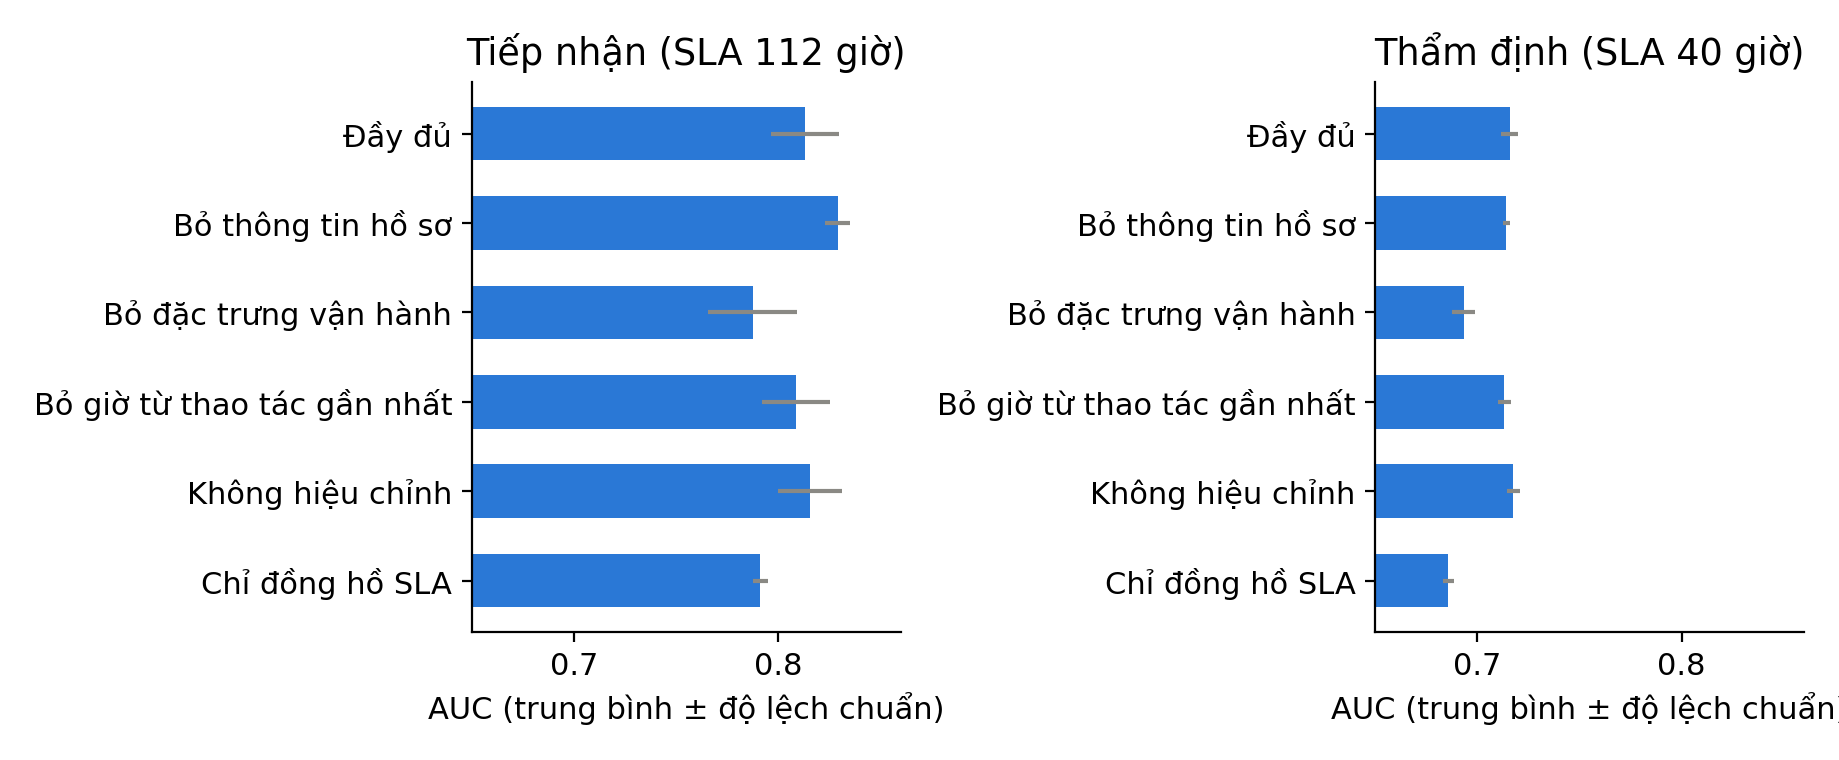

results/figures/nguong_tham_dinh.png


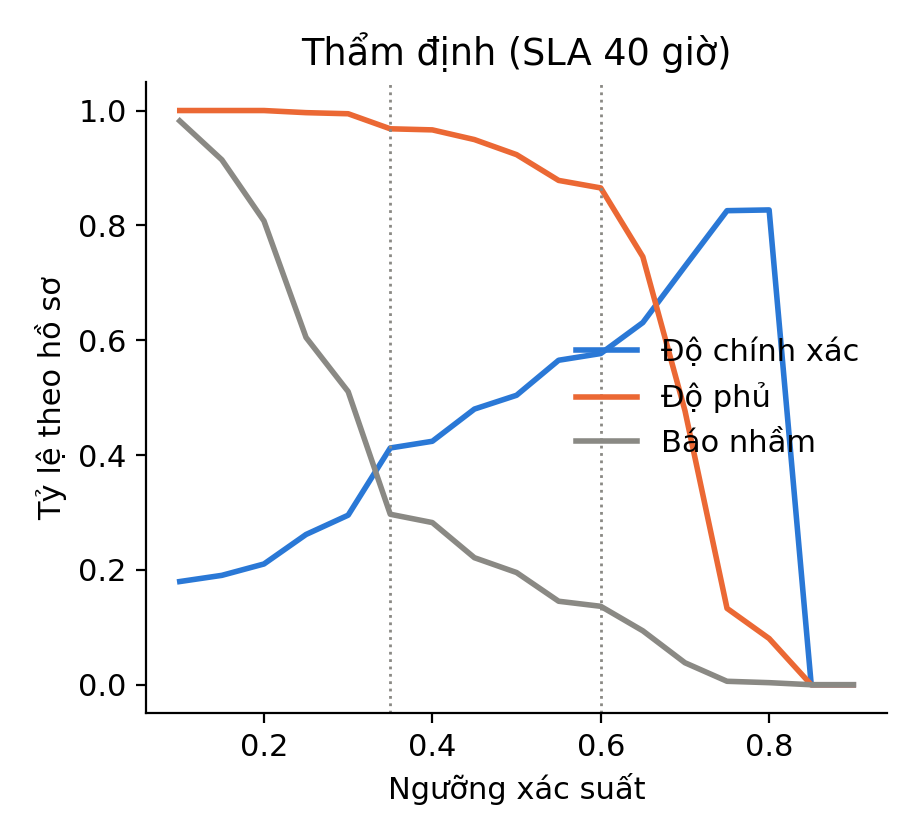

results/figures/nguong_tiep_nhan.png


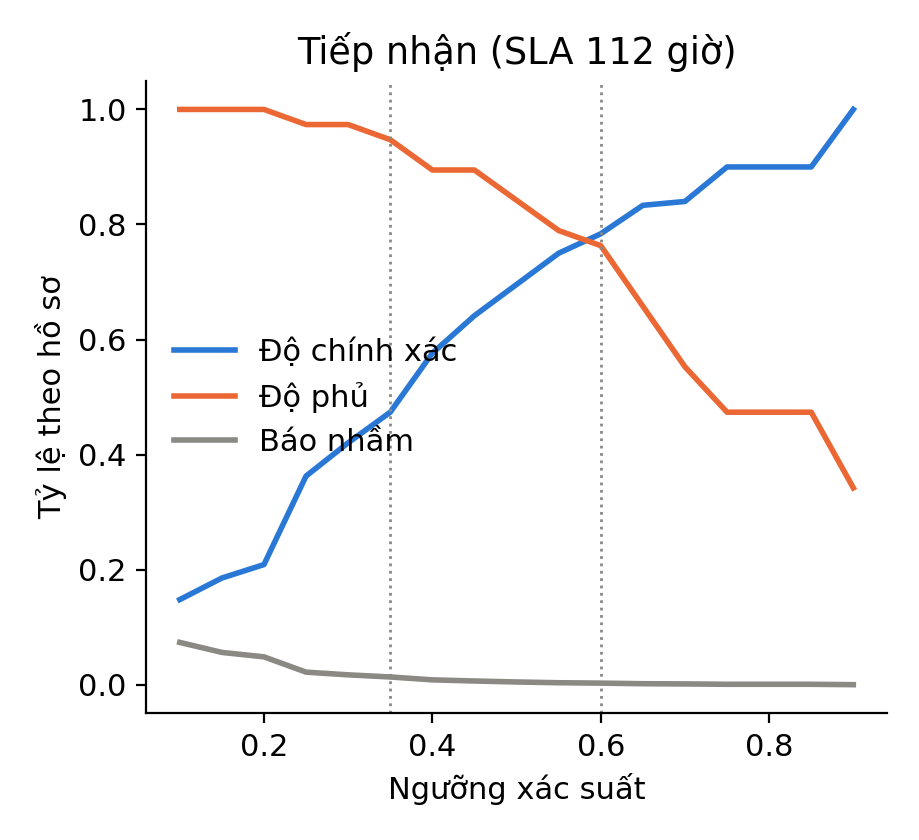

results/figures/roc_tham_dinh.png


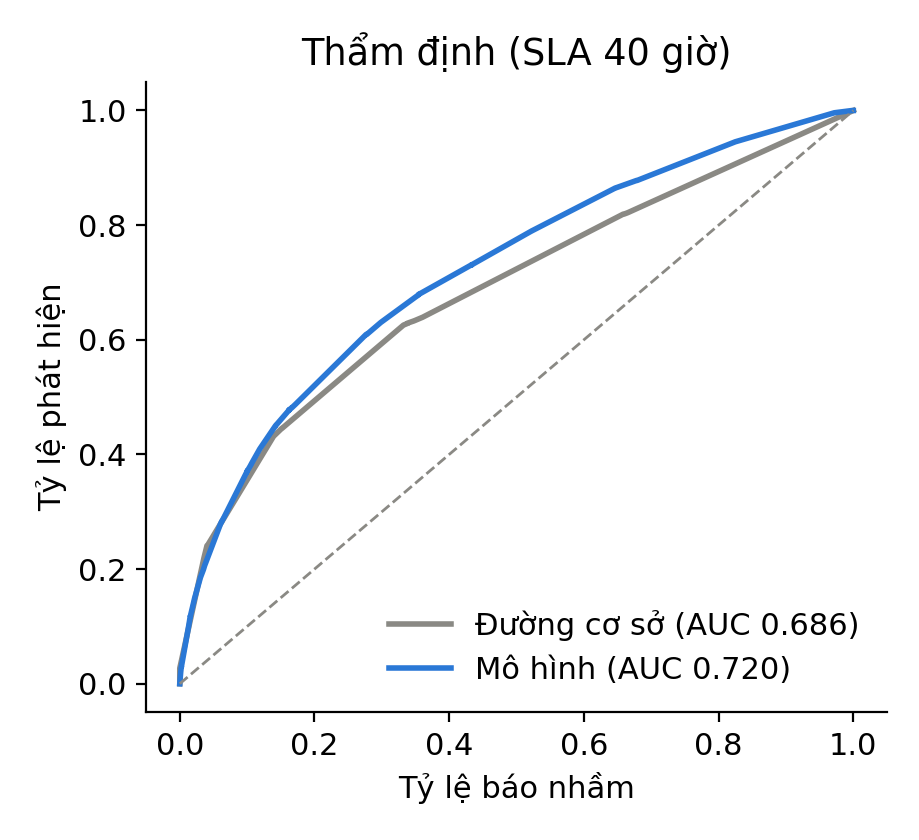

results/figures/roc_tiep_nhan.png


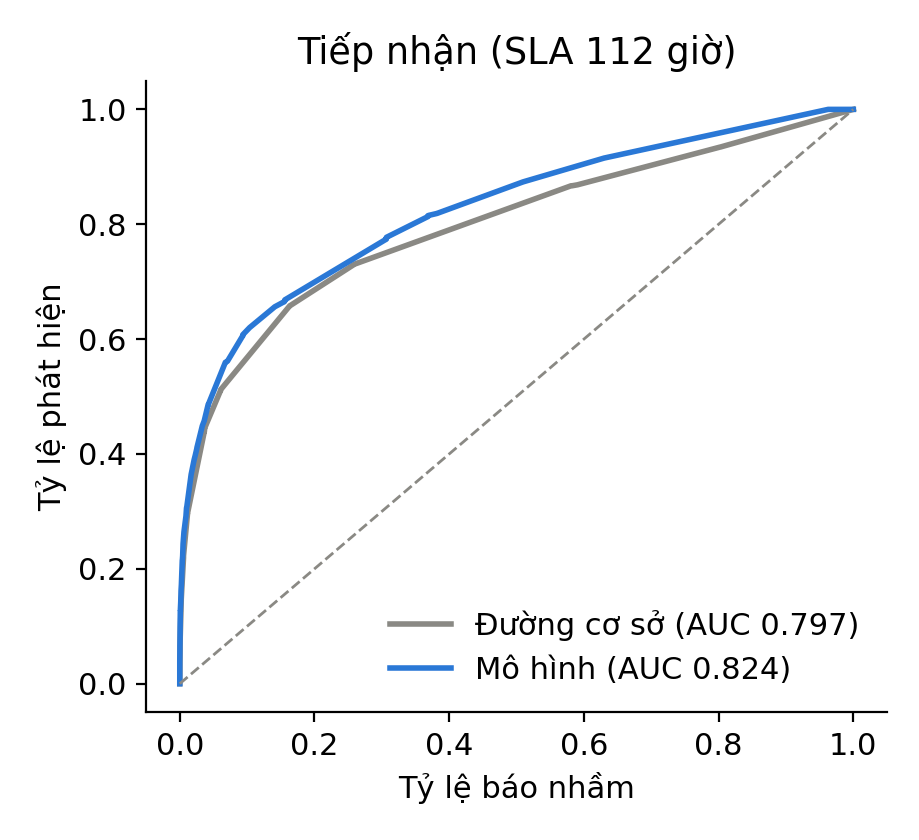

results/figures/sla_nhan_biet.png


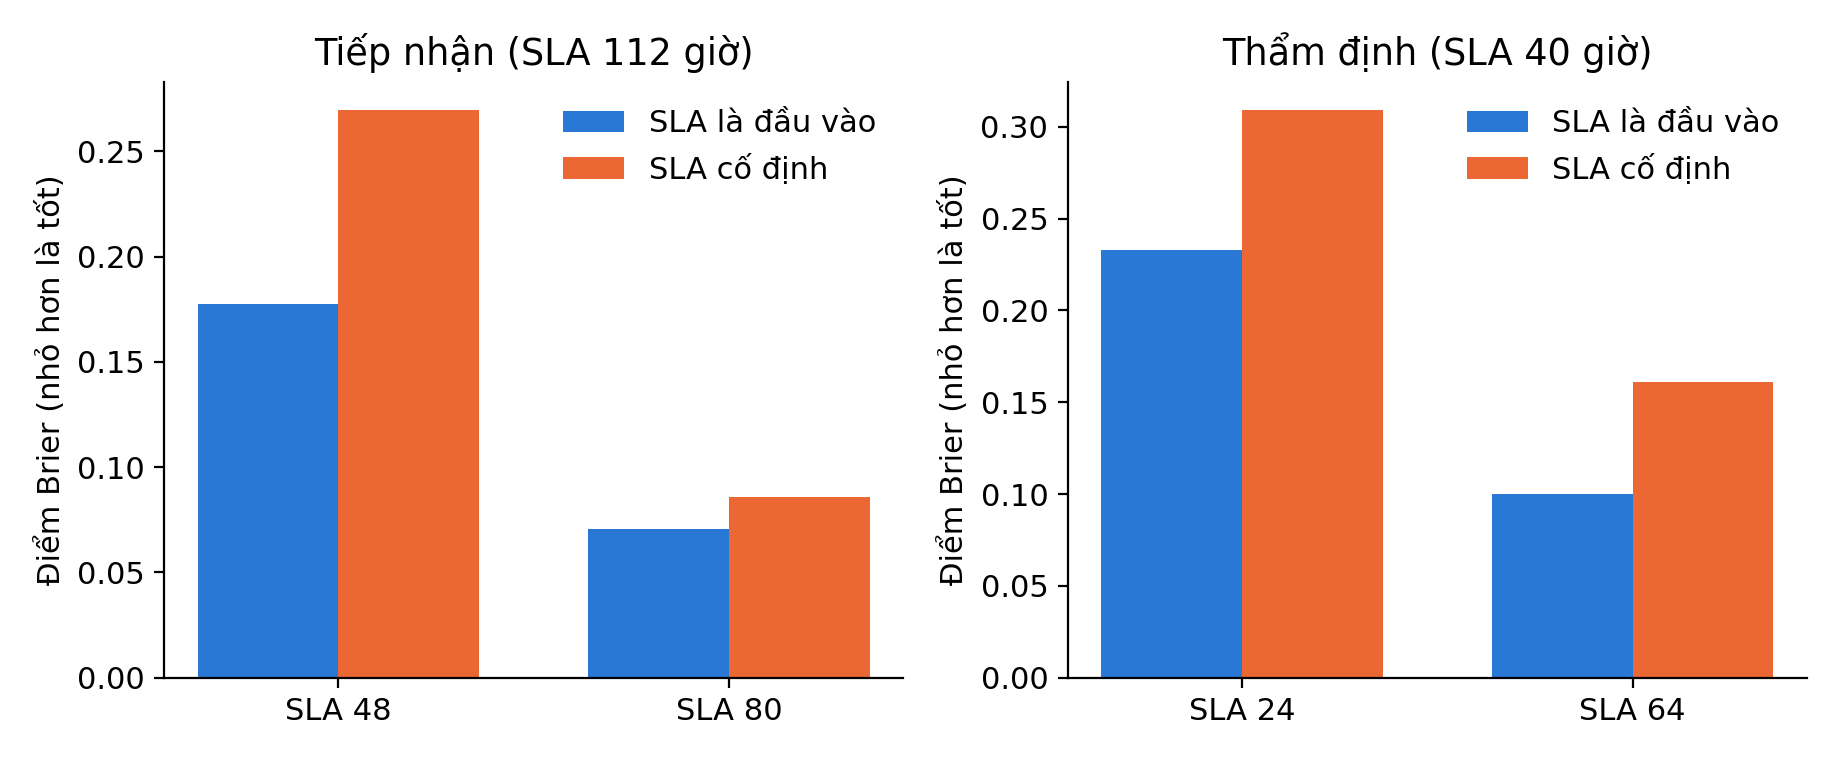

In [11]:
import json, glob
d = json.load(open("results/diagnostics_v4.json"))
print("Trần lý thuyết, kiểm tra khớp dữ liệu hiện có:", d["oracle"]["check"])
for s in ("tiep_nhan", "tham_dinh"):
    o = d["oracle"][s]
    print("")
    print("==", s, "- số hồ sơ dùng:", o["cases_used"])
    for k in ("lr_observable", "lr_with_hidden", "gb_observable", "gb_with_hidden"):
        print("  ", k.ljust(16), "AUC %.4f  Brier %.4f" % (o[k]["auc"], o[k]["brier"]))
    r = d["reasons"][s]
    print("  Lý do giải thích, tỷ lệ theo nhóm:", r["share_by_group"], "| dòng có ít nhất 1 lý do:", r["rows_with_at_least_one_reason"], "/", r["rows_explained"])
print("")
print("Độ nhạy theo giả định mô phỏng (AUC mô hình đang dùng trừ AUC đường cơ sở):")
for name, v in d["sensitivity"].items():
    print("  ", name.ljust(40), {k: x["gain_chosen_vs_base"] for k, x in v.items() if isinstance(x, dict)})
from IPython.display import Image, display
for f in sorted(glob.glob("results/figures/*.png")):
    print(f)
    display(Image(f, width=520))

## 8. Tải kết quả về máy (làm bằng chứng)

In [ ]:
!zip -q -r ket-qua-v4.zip results models
from google.colab import files
files.download("ket-qua-v4.zip")   # Kaggle: tệp nằm ở thư mục Output, không cần ô này